# Gaussian Process on the imported Working_final_maps concert field

This GP-only notebook reads `仿真/andreib/Working_final_maps/concert_map.py` and `extract_sound_venues.py` directly. It runs a fixed GP and a GP whose length scale is selected from microphone observations. Both use the same 15 microphone configurations. The notebook shows the full configuration overview, all numerical results, one 100-grid reconstruction with microphone positions, and error trends.

The concert scene is static and synthetic. Values are unweighted sound levels in dB, not measurements from real smartphones.

## 1. Locate the imported map and run the experiment

Run the cells from top to bottom. Outputs are saved in a separate `gp_working_final_maps_output` folder, so the earlier GP run remains available. The next cell confirms the exact source directory before any prediction is made.

In [1]:
from pathlib import Path
import csv
import sys
import numpy as np
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
ROOT = next((folder for folder in (current, *current.parents)
             if (folder / '仿真' / 'austin' / 'gp_working_final_maps.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the MDM3 project.')
sys.path.insert(0, str(ROOT / '仿真' / 'austin'))
OUTPUT = ROOT / 'gp_working_final_maps_output'
INPUTS = OUTPUT / 'model_inputs'
PREDICTIONS = OUTPUT / 'gp_predictions'
EVALUATION = OUTPUT / 'evaluation_only'
print('Project:', ROOT)
from gp_working_final_maps import TEAM_DIR, main
print('Imported map directory:', TEAM_DIR)


Project: /Users/a603/Desktop/MDM3


Imported map directory: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps


### GP settings and evaluation boundary

- **Fixed GP:** RBF length scale 15 m.
- **Phone-CV GP:** select one of 1, 2, 3, 5, 8, or 15 m using five-fold cross-validation on microphone readings only, separately for each configuration.
- Both settings use a 15 dB signal standard deviation and an assumed 0.5 dB observation-noise standard deviation. They receive the same microphone positions and readings.
- The full synthetic field is read only after prediction to calculate audience-area evaluation scores. It is never used to choose the GP length scale.

In [2]:
fixed_results, tuned_results = main()
print(f'Completed {len(fixed_results)} fixed and {len(tuned_results)} phone-CV GP runs.')

 10 random   : fixed RMSE 1.85 dB | phone-CV RMSE 1.98 dB (length scale 8 m)
 30 random   : fixed RMSE 1.66 dB | phone-CV RMSE 1.66 dB (length scale 15 m)
 50 random   : fixed RMSE 1.64 dB | phone-CV RMSE 0.92 dB (length scale 5 m)
100 random   : fixed RMSE 1.51 dB | phone-CV RMSE 0.63 dB (length scale 3 m)
250 random   : fixed RMSE 1.45 dB | phone-CV RMSE 0.18 dB (length scale 2 m)
 10 grid     : fixed RMSE 1.89 dB | phone-CV RMSE 1.78 dB (length scale 3 m)
 30 grid     : fixed RMSE 1.57 dB | phone-CV RMSE 1.59 dB (length scale 5 m)
 50 grid     : fixed RMSE 1.48 dB | phone-CV RMSE 1.10 dB (length scale 8 m)


100 grid     : fixed RMSE 1.45 dB | phone-CV RMSE 0.36 dB (length scale 2 m)
250 grid     : fixed RMSE 1.39 dB | phone-CV RMSE 0.15 dB (length scale 2 m)
 10 clustered: fixed RMSE 12.75 dB | phone-CV RMSE 9.83 dB (length scale 8 m)
 30 clustered: fixed RMSE 13.80 dB | phone-CV RMSE 4.61 dB (length scale 2 m)
 50 clustered: fixed RMSE 13.17 dB | phone-CV RMSE 4.98 dB (length scale 1 m)
100 clustered: fixed RMSE 15.65 dB | phone-CV RMSE 4.71 dB (length scale 1 m)


250 clustered: fixed RMSE 21.97 dB | phone-CV RMSE 4.10 dB (length scale 2 m)


Saved 15 baseline and 15 phone-CV configurations in: /Users/a603/Desktop/MDM3/gp_working_final_maps_output
Completed 15 fixed and 15 phone-CV GP runs.


## 2. Confirm source files and inspect all 15 results

The source list records absolute paths and SHA-256 hashes for the imported field generator, sampler, and wall model. `phone_positions` has shape `(N, 2)`; `phone_levels` has `(1, N)`; each prediction has `(1, M)` for the permitted audience cells. A negative peak gap means the predicted maximum is below the true maximum.

In [3]:
with (OUTPUT / 'source_files.csv').open(newline='') as file:
    source_rows = list(csv.DictReader(file))
for item in source_rows:
    print('Source:', item['path'], '| SHA-256:', item['sha256'][:16] + '...')

with np.load(INPUTS / 'observations_100_grid.npz', allow_pickle=False) as sample:
    print('100-grid phone positions:', sample['phone_positions'].shape)
    print('100-grid observed levels:', sample['phone_levels'].shape)
print('Audience query positions:', np.load(INPUTS / 'query_positions.npy').shape)
print('Fixed GP prediction:', np.load(PREDICTIONS / 'prediction_100_grid.npy').shape)
print('Phone-CV GP prediction:', np.load(PREDICTIONS / 'prediction_tuned_100_grid.npy').shape)

def read_csv(path):
    with path.open(newline='') as file:
        return list(csv.DictReader(file))

fixed_rows = read_csv(EVALUATION / 'overall_metrics.csv')
tuned_rows = read_csv(EVALUATION / 'overall_metrics_tuned.csv')
selection_rows = read_csv(PREDICTIONS / 'selected_length_scales.csv')
if len(fixed_rows) != len(tuned_rows) or len(fixed_rows) != len(selection_rows) or len(fixed_rows) != 15:
    raise ValueError('Expected 15 aligned configurations in each result table')
lines = ['| Phones | Layout | Selected scale (m) | Phone CV RMSE | Fixed map RMSE | CV map RMSE | CV peak gap |',
         '|---:|---|---:|---:|---:|---:|---:|']
for a, b, s in zip(fixed_rows, tuned_rows, selection_rows):
    if (a['phone_count'], a['layout']) != (b['phone_count'], b['layout']) or (a['phone_count'], a['layout']) != (s['phone_count'], s['layout']):
        raise ValueError('Result rows are not aligned')
    lines.append(f"| {a['phone_count']} | {a['layout']} | {float(s['selected_length_scale_m']):g} | "
                 f"{float(s['phone_cv_RMSE_db']):.2f} | {float(a['RMSE_db']):.2f} | "
                 f"{float(b['RMSE_db']):.2f} | {float(b['peak_gap_db']):+.2f} |")
display(Markdown('\n'.join(lines)))

Source: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/concert_map.py | SHA-256: fc25c9049599de9f...
Source: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/extract_sound_venues.py | SHA-256: 211ddf81badf7bbe...
Source: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/single_wall.py | SHA-256: d64036025d72029f...
100-grid phone positions: (100, 2)
100-grid observed levels: (1, 100)
Audience query positions: (17390, 2)
Fixed GP prediction: (1, 17390)
Phone-CV GP prediction: (1, 17390)


| Phones | Layout | Selected scale (m) | Phone CV RMSE | Fixed map RMSE | CV map RMSE | CV peak gap |
|---:|---|---:|---:|---:|---:|---:|
| 10 | random | 8 | 1.11 | 1.85 | 1.98 | -7.60 |
| 30 | random | 15 | 0.64 | 1.66 | 1.66 | -7.97 |
| 50 | random | 5 | 0.63 | 1.64 | 0.92 | -5.94 |
| 100 | random | 3 | 0.21 | 1.51 | 0.63 | -5.17 |
| 250 | random | 2 | 0.27 | 1.45 | 0.18 | +0.41 |
| 10 | grid | 3 | 1.83 | 1.89 | 1.78 | -9.42 |
| 30 | grid | 5 | 2.44 | 1.57 | 1.59 | +0.76 |
| 50 | grid | 8 | 1.94 | 1.48 | 1.10 | -4.32 |
| 100 | grid | 2 | 0.95 | 1.45 | 0.36 | +1.47 |
| 250 | grid | 2 | 0.24 | 1.39 | 0.15 | +1.19 |
| 10 | clustered | 8 | 1.33 | 12.75 | 9.83 | +17.60 |
| 30 | clustered | 2 | 0.44 | 13.80 | 4.61 | -0.19 |
| 50 | clustered | 1 | 0.44 | 13.17 | 4.98 | +0.15 |
| 100 | clustered | 1 | 0.31 | 15.65 | 4.71 | +0.33 |
| 250 | clustered | 2 | 0.26 | 21.97 | 4.10 | +0.18 |

**How to read the table:** “Phone CV RMSE” measures how well one held-out microphone is predicted from other microphones; “map RMSE” measures the final reconstruction across the entire audience region. They are different tests. A lower phone CV error does not guarantee a lower whole-map error when microphones miss a large region. Some small-sample configurations do become slightly worse after tuning. The chosen length scale can vary with the sample locations.

## 3. All 15 microphone configurations

Each panel uses the same concert sound field, with red dots marking microphone positions. Rows vary the number of microphones; columns vary the layout. The concert map has one static frame, so this figure shows frame 0. These are the exact samples passed to both GP settings.

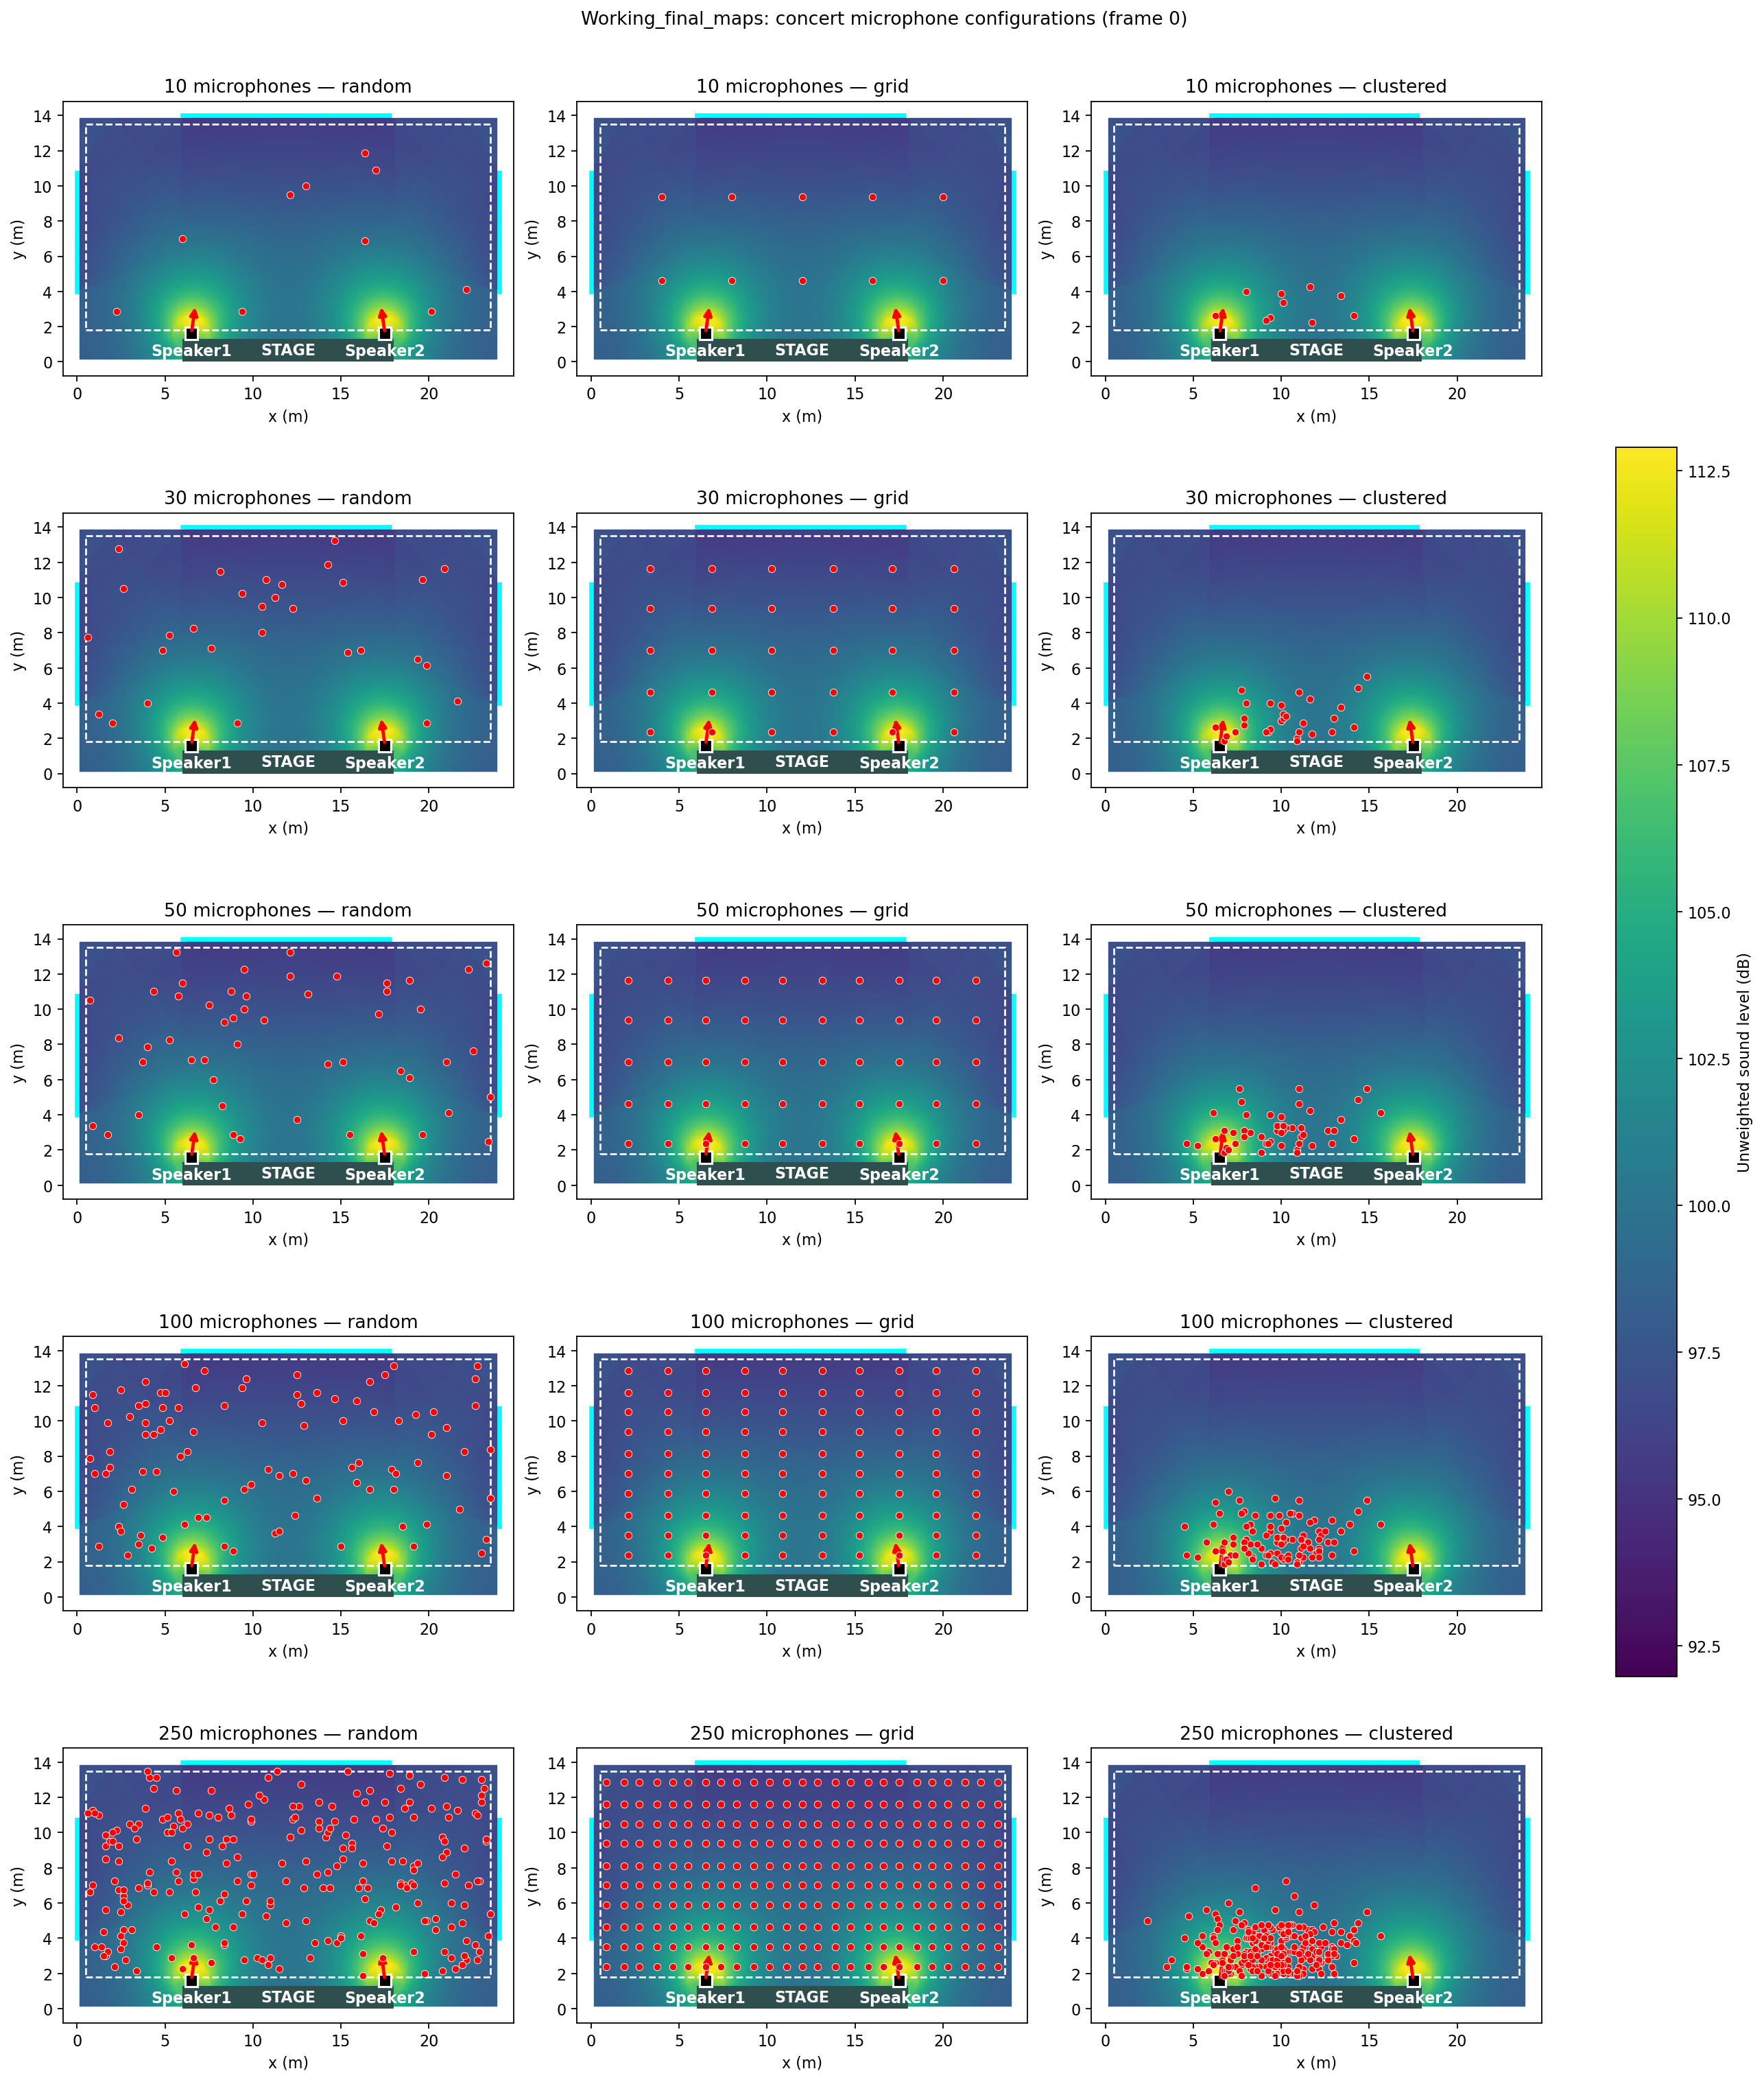

In [4]:
display(Image(filename=str(EVALUATION / 'concert_all_microphone_configurations.png')))

## 4. True field, two GP predictions, and absolute error

The first three maps share one sound-level colour scale. Red dots on the fixed GP, phone-CV GP, and error maps mark the same 100 grid microphones. White cells lie outside the audience area and are excluded from scoring. The fourth map shows the phone-CV GP's absolute error in dB.

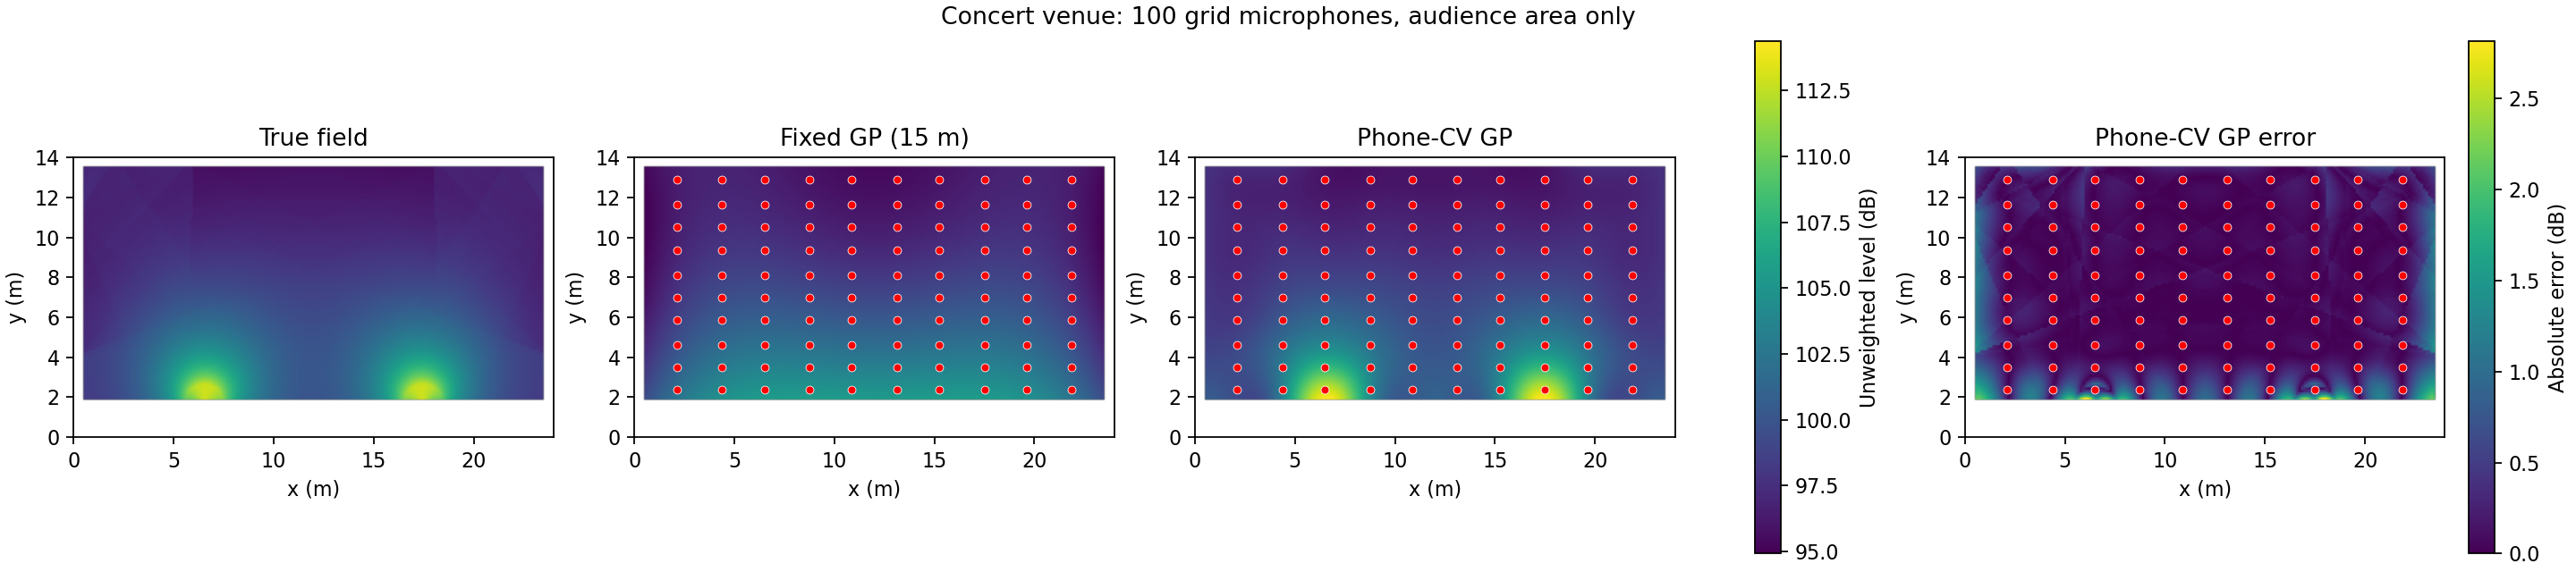

In [5]:
display(Image(filename=str(EVALUATION / 'concert_gp_baseline_vs_tuned_100_grid.png')))

## 5. Error across microphone counts and layouts

Each panel compares the fixed and phone-CV GP under one layout. Every pair receives exactly the same microphone data. The plotted RMSE is evaluated against the full audience-area synthetic truth after each prediction is complete.

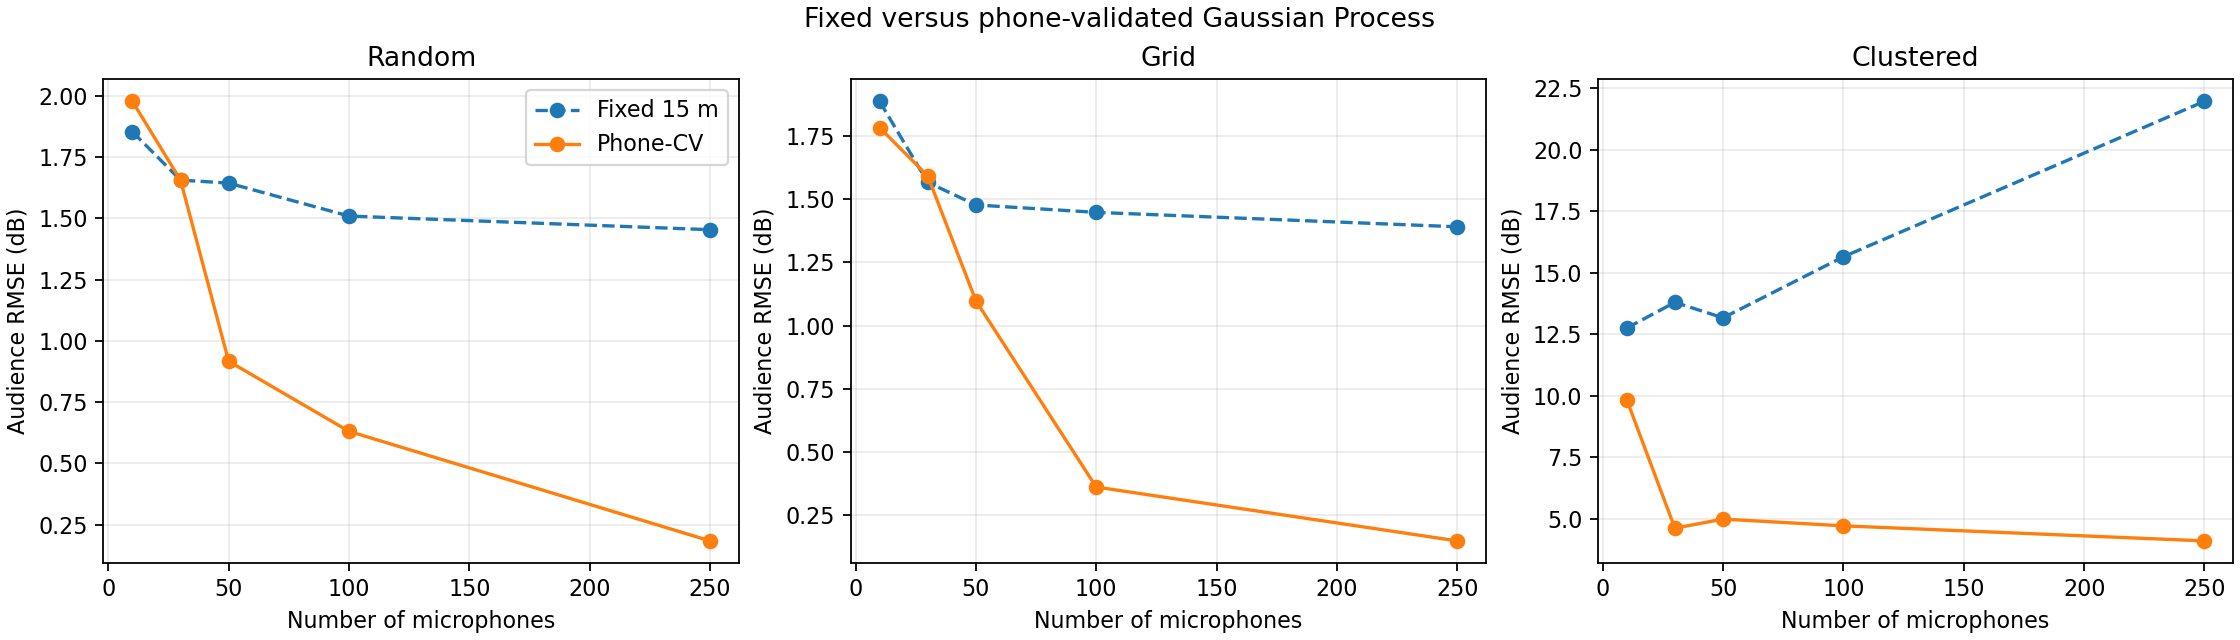

In [6]:
display(Image(filename=str(EVALUATION / 'concert_gp_baseline_vs_tuned_rmse.png')))

## 6. Inspect length-scale selection for the 100-grid example

The table below reports held-out microphone RMSE for every candidate length scale. The full `phone_cv_scores.csv` contains all 90 candidate scores: 15 configurations × 6 candidates. These scores use observed microphones only.

In [7]:
cv_rows = read_csv(PREDICTIONS / 'phone_cv_scores.csv')
example_cv = [r for r in cv_rows if r['phone_count'] == '100' and r['layout'] == 'grid']
lines = ['| Length scale (m) | Held-out phone RMSE (dB) |', '|---:|---:|']
for r in example_cv:
    lines.append(f"| {float(r['length_scale_m']):g} | {float(r['phone_cv_RMSE_db']):.3f} |")
display(Markdown('\n'.join(lines)))

| Length scale (m) | Held-out phone RMSE (dB) |
|---:|---:|
| 1 | 1.650 |
| 2 | 0.947 |
| 3 | 1.274 |
| 5 | 1.421 |
| 8 | 1.567 |
| 15 | 1.871 |

## 7. Saved outputs and limits

- `source_files.csv`: exact `Working_final_maps` input paths and file hashes.
- `model_inputs/`: all 15 observation sets, common audience query positions, and the audience mask.
- `gp_predictions/`: 15 fixed and 15 phone-CV prediction arrays, selected length scales, all cross-validation scores, and model settings.
- `evaluation_only/`: synthetic truth, two 15-row metric tables, the 15-layout overview, the four-panel GP map, and error trend figures.
- `run_manifest.csv`: observation and prediction filenames for each configuration.

This is one simulated concert field and one sampling seed (`42`). The experiment does not establish performance on another venue, another seed, or real phones. The GP predicts sound level in dB directly. The full truth remains separate from parameter selection.